# Disk Array Failure Tolerance

Probability that **cumulative disk failures stay within an array's tolerance** over $t$ years, with **independent disk failures and no disk replacement**. This is a model of redundancy exhaustion, not the probability of avoiding every cause of data loss.

## Model

All $n$ disks share the same failure probability for each year. For constant yearly failure probability $q$, per-disk cumulative failure is $p(t)=1-(1-q)^t$. An array tolerating any $k$ failed disks (for example, a single RAID-Z2 group has $k=2$) stays within that tolerance with probability:

$$P(F_t \le k)=\sum_{i=0}^{k}\binom{n}{i}p(t)^i(1-p(t))^{n-i}$$

Failed disks remain failed. Correlated failures, unreadable sectors, controller faults, accidental deletion and rebuilds are outside this model. **No replacement is an explicit scenario, not a worst-case bound.**

## Constant-rate examples

With an exponential lifetime assumption, an assumed MTBF gives $q=1-e^{-8766/\mathrm{MTBF}}$. These rounded example inputs do not describe every model in a product category or account for aging.

| Assumed MTBF | Constant yearly failure probability $q$ |
|---|---|
| 1,000,000 h | 0.87% |
| 1,500,000 h | 0.58% |
| 2,500,000 h | 0.35% |

## Backblaze statistics for context

[Drive Stats 2024](https://www.backblaze.com/blog/backblaze-drive-stats-for-2024/) · [Official dataset and 2025 annual summary](https://www.backblaze.com/cloud-storage/resources/hard-drive-test-data)

| Population and reporting window | Annualized failure rate (AFR) |
|---|---|
| Qualifying models, calendar year 2024 | 1.57% |
| Qualifying in-service models, lifetime through the end of 2024 | 1.31% |
| 20TB+ group, Q4 2024 | 0.77% |
| Seagate ST16000NM002J, calendar year 2024 | 0.22% |
| Fleet annual summary, calendar year 2025 | 1.36% |

AFR is a fleet statistic annualized from failures and drive-days; populations, ages and reporting windows differ. It is not exactly a one-year failure probability or an age-specific survival curve for a new disk. The figures give a sense of scale, not a universal planning rate.

In [1]:
from math import comb
import numpy as np
import plotly.graph_objects as go


def tolerance_probability(n: int, k: int, yearly_probability: float,
                          years: np.ndarray) -> np.ndarray:
    """P(cumulative independent failures <= k), with identical disks and no replacement."""
    p = 1 - (1 - yearly_probability) ** years
    return np.array([
        sum(comb(n, i) * pt ** i * (1 - pt) ** (n - i) for i in range(k + 1))
        for pt in p
    ])


def tolerance_probability_varying(n: int, k: int,
                                  yearly_probabilities: np.ndarray) -> np.ndarray:
    """Same model with assumed conditional failure probabilities for successive years."""
    p = 1 - np.cumprod(1 - yearly_probabilities)
    return np.array([
        sum(comb(n, i) * pt ** i * (1 - pt) ** (n - i) for i in range(k + 1))
        for pt in p
    ])

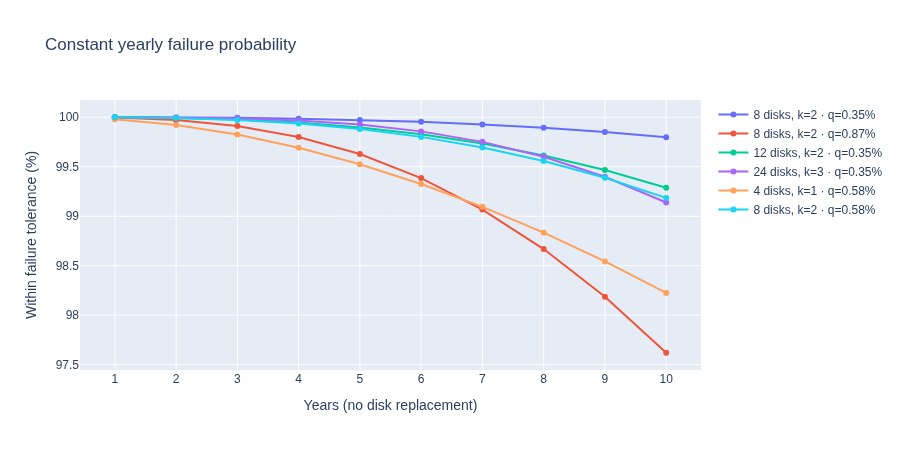

In [2]:
MAX_YEARS = 10
years = np.arange(1, MAX_YEARS + 1)

# Rounded MTBF-derived example probabilities; no product-category predictions.
constant_scenarios = [
    ("8 disks, k=2 · q=0.35%",   8, 2, 0.0035),
    ("8 disks, k=2 · q=0.87%",   8, 2, 0.0087),
    ("12 disks, k=2 · q=0.35%", 12, 2, 0.0035),
    ("24 disks, k=3 · q=0.35%", 24, 3, 0.0035),
    ("4 disks, k=1 · q=0.58%",   4, 1, 0.0058),
    ("8 disks, k=2 · q=0.58%",   8, 2, 0.0058),
]
constant_results = {
    label: tolerance_probability(n, k, q, years)
    for label, n, k, q in constant_scenarios
}

fig = go.Figure()
for label, probs in constant_results.items():
    fig.add_trace(go.Scatter(x=years, y=probs * 100, mode="lines+markers", name=label))
fig.update_xaxes(title_text="Years (no disk replacement)", dtick=1)
fig.update_yaxes(title_text="Within failure tolerance (%)")
fig.update_layout(title_text="Constant yearly failure probability", height=450, width=900)
fig.show()

## Hypothetical aging sensitivity

The next chart multiplies an assumed base probability by **1× in years 1–4, 2× in years 5–6, and 4× from year 7**. This schedule is an illustrative sensitivity scenario, not a fitted bathtub curve or an observed Backblaze aging law.

Base probabilities are **0.7%** and **1.3%**; the fleet statistics above provide context only. For each year, the chosen probability applies to disks still working at its start. The same independent-failure, no-replacement model then accumulates failures.

Read the lines as “what if failure probabilities increase this way?” Changing disk count, tolerance or the assumed schedule changes the answer; the chart does not predict the service life of a particular array.

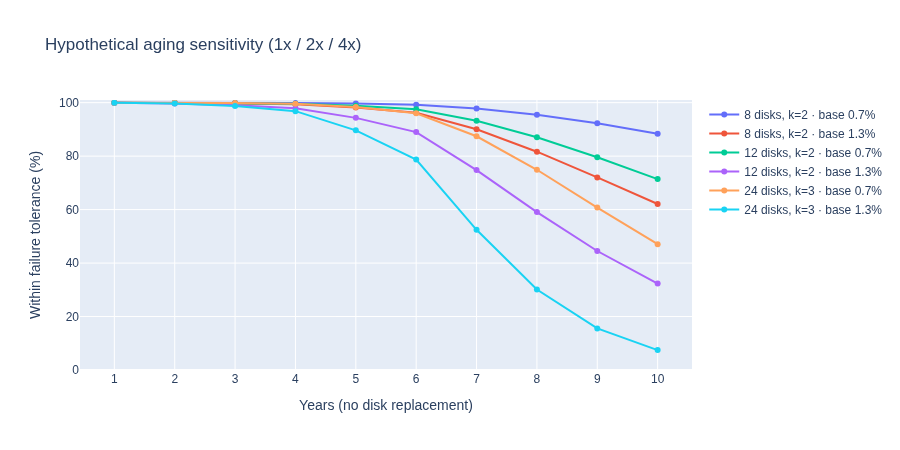

In [3]:
def hypothetical_aging_probabilities(base_probability, n_years=10):
    # Author-chosen sensitivity schedule, not fitted to observed drive ages.
    return np.array([
        base_probability * (1 if y <= 4 else 2 if y <= 6 else 4)
        for y in range(1, n_years + 1)
    ])


BASE_PROBABILITIES = (0.007, 0.013)  # Illustrative levels, not fleet forecasts.
aging_configs = [(8, 2), (12, 2), (24, 3)]
aging_results = {}
for n, k in aging_configs:
    for base in BASE_PROBABILITIES:
        label = f"{n} disks, k={k} · base {base:.1%}"
        aging_results[label] = tolerance_probability_varying(
            n, k, hypothetical_aging_probabilities(base, MAX_YEARS)
        )

fig = go.Figure()
for label, probs in aging_results.items():
    fig.add_trace(go.Scatter(x=years, y=probs * 100, mode="lines+markers", name=label))
fig.update_xaxes(title_text="Years (no disk replacement)", dtick=1)
fig.update_yaxes(title_text="Within failure tolerance (%)", range=[0, 101])
fig.update_layout(title_text="Hypothetical aging sensitivity (1x / 2x / 4x)", height=450, width=900)
fig.show()